# Datheon Internship - Task 2
## Real Estate Housing Price Prediction (Ridge & Lasso Regression)
Applicant: Azmain Haq Siam
Application ID: DT-2026-YN1B7

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.base import BaseEstimator, TransformerMixin

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [3]:
df = pd.read_csv("data/california_housing.csv")
print("Dataset Shape:", df.shape)
display(df.head())
display(df.info())

Dataset Shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


None

In [4]:
print("Missing Values:")
display(df.isnull().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("Dataset Statistics:")
display(df.describe())
print("Ocean Proximity:")
display(df["ocean_proximity"].value_counts())

Missing Values:


longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Duplicate Rows: 0
Dataset Statistics:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


Ocean Proximity:


ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

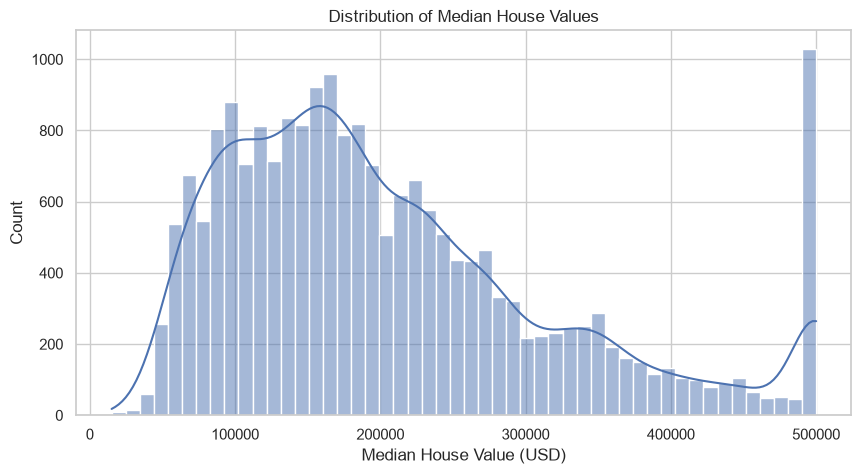

In [5]:
plt.figure(figsize=(10, 5))
sns.histplot(df["median_house_value"], bins=50, kde=True)
plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value (USD)")
plt.show()

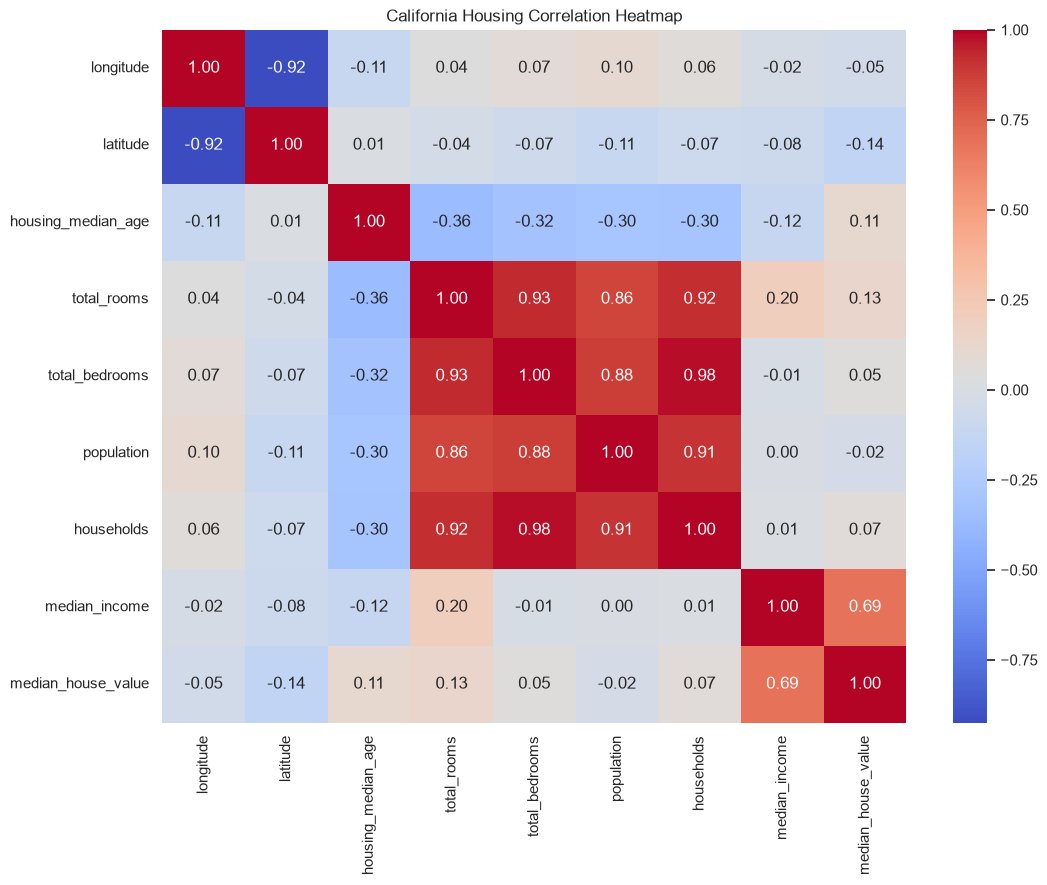

In [6]:
plt.figure(figsize=(12, 9))
correlation = df.select_dtypes(include=np.number).corr()
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("California Housing Correlation Heatmap")
plt.show()

In [7]:
X = df.drop(columns=["median_house_value"])
y = df["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)
print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (16512, 9)
Testing: (4128, 9)


In [8]:
class HousingFeatureEngineer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = X.copy()
        X["rooms_per_household"] = (X["total_rooms"] / X["households"].replace(0, np.nan))
        X["bedrooms_per_room"] = (X["total_bedrooms"] / X["total_rooms"].replace(0, np.nan))
        X["population_per_household"] = (X["population"] / X["households"].replace(0, np.nan))
        return X

In [9]:
numeric_features = ["longitude", "latitude", "housing_median_age", "total_rooms", "total_bedrooms", "population", "households", "median_income", "rooms_per_household", "bedrooms_per_room", "population_per_household"]
categorical_features = ["ocean_proximity"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

def create_pipeline(model):
    return Pipeline([
        ("feature_engineering", HousingFeatureEngineer()),
        ("preprocessing", preprocessor),
        ("regressor", model)
    ])

In [10]:
def evaluate_model(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {"RMSE": rmse, "MAE": mae, "R2": r2}

In [11]:
ols_model = create_pipeline(LinearRegression())
ols_model.fit(X_train, y_train)
ols_pred = ols_model.predict(X_test)
ols_results = evaluate_model(y_test, ols_pred)
print("OLS Results:")
print(ols_results)

OLS Results:
{'RMSE': np.float64(69127.03829924985), 'MAE': 49645.49244453642, 'R2': 0.635339233523819}


In [12]:
alpha_values = np.logspace(-2, 3, 10)
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

ridge_pipeline = create_pipeline(Ridge())
ridge_search = GridSearchCV(
    ridge_pipeline,
    param_grid={"regressor__alpha": alpha_values},
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    refit=True
)
ridge_search.fit(X_train, y_train)
ridge_model = ridge_search.best_estimator_
ridge_pred = ridge_model.predict(X_test)

print("Best Ridge Parameters:")
print(ridge_search.best_params_)
print("Ridge Results:")
print(evaluate_model(y_test, ridge_pred))

Best Ridge Parameters:
{'regressor__alpha': np.float64(1.6681005372000592)}
Ridge Results:
{'RMSE': np.float64(69139.66548541367), 'MAE': 49655.32593173616, 'R2': 0.6352059988285492}


In [13]:
lasso_pipeline = create_pipeline(Lasso(max_iter=20000, tol=1e-3))
lasso_search = GridSearchCV(
    lasso_pipeline,
    param_grid={"regressor__alpha": alpha_values},
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    refit=True
)
lasso_search.fit(X_train, y_train)
lasso_model = lasso_search.best_estimator_
lasso_pred = lasso_model.predict(X_test)

print("Best Lasso Parameters:")
print(lasso_search.best_params_)
print("Lasso Results:")
print(evaluate_model(y_test, lasso_pred))

Best Lasso Parameters:
{'regressor__alpha': np.float64(5.994842503189409)}
Lasso Results:
{'RMSE': np.float64(69134.26184126975), 'MAE': 49651.153607832595, 'R2': 0.6352630179050409}


In [14]:
predictions = {"OLS": ols_pred, "Ridge": ridge_pred, "Lasso": lasso_pred}
results = pd.DataFrame({name: evaluate_model(y_test, pred) for name, pred in predictions.items()}).T
results.index.name = "Model"
display(results)
print("Best Model:", results["RMSE"].idxmin())

,RMSE,MAE,R2
Model,,,
OLS,69127.038299,49645.492445,0.635339
Ridge,69139.665485,49655.325932,0.635206
Lasso,69134.261841,49651.153608,0.635263


Best Model: OLS


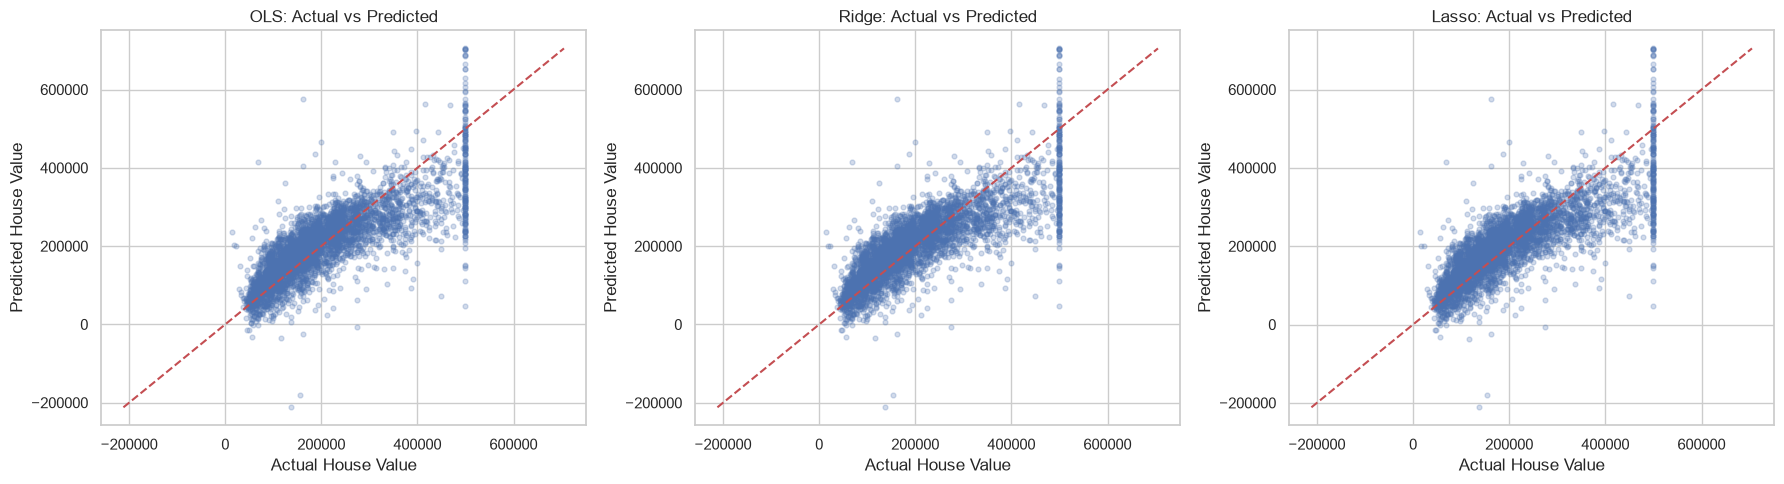

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, pred, alpha=0.25, s=12)
    minimum = min(y_test.min(), pred.min())
    maximum = max(y_test.max(), pred.max())
    ax.plot([minimum, maximum], [minimum, maximum], "r--")
    ax.set_title(f"{name}: Actual vs Predicted")
    ax.set_xlabel("Actual House Value")
    ax.set_ylabel("Predicted House Value")
plt.tight_layout()
plt.show()

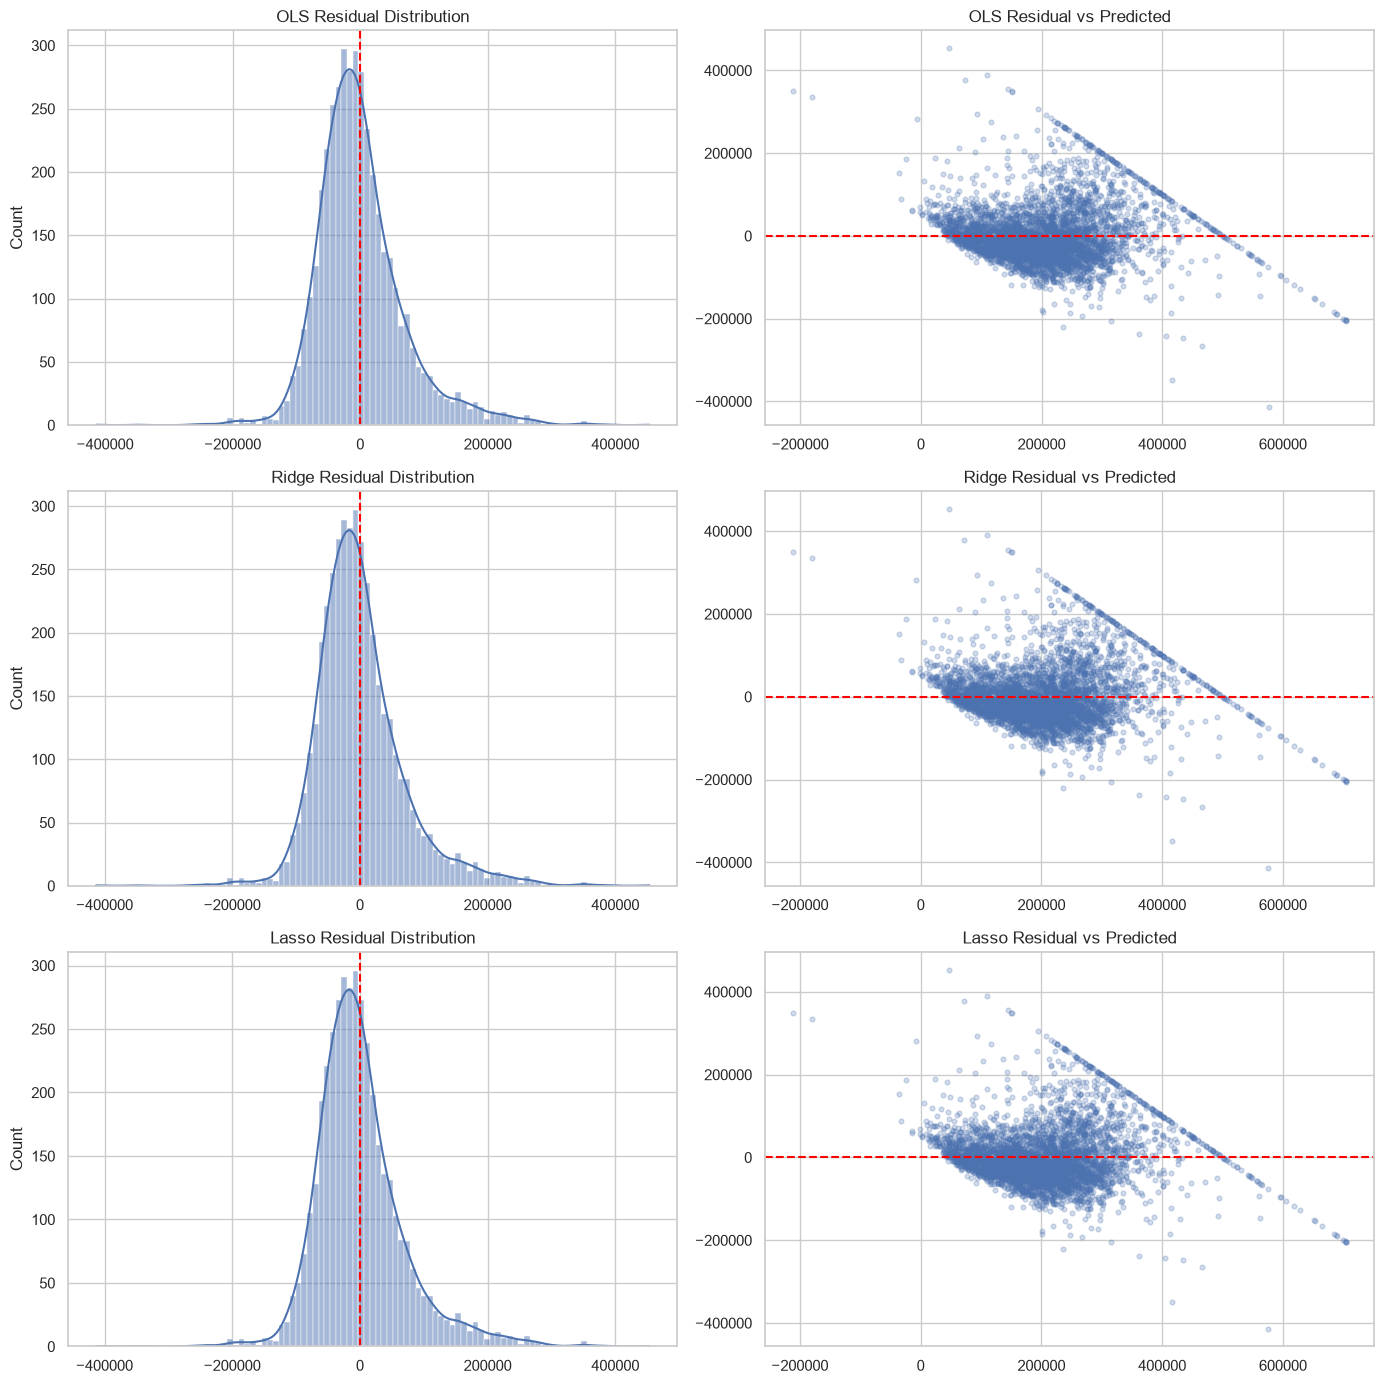

In [16]:
fig, axes = plt.subplots(3, 2, figsize=(14, 14))
for row, (name, pred) in enumerate(predictions.items()):
    residuals = y_test.values - pred
    sns.histplot(residuals, kde=True, ax=axes[row, 0])
    axes[row, 0].axvline(0, color="red", linestyle="--")
    axes[row, 0].set_title(f"{name} Residual Distribution")
    
    axes[row, 1].scatter(pred, residuals, alpha=0.25, s=12)
    axes[row, 1].axhline(0, color="red", linestyle="--")
    axes[row, 1].set_title(f"{name} Residual vs Predicted")
plt.tight_layout()
plt.show()

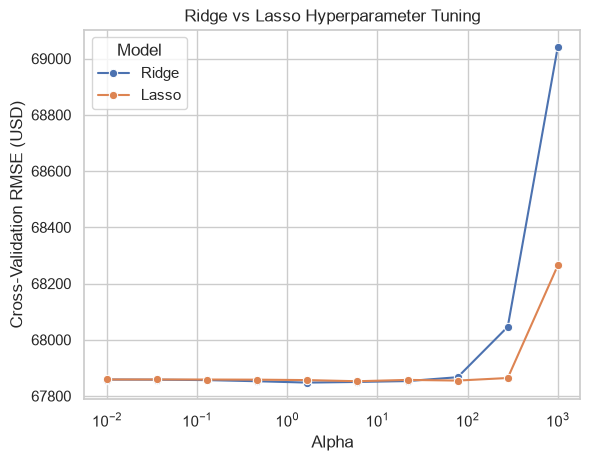

In [17]:
def get_cv_results(search, model_name):
    data = pd.DataFrame(search.cv_results_)
    return pd.DataFrame({
        "Model": model_name,
        "Alpha": data["param_regressor__alpha"].astype(float),
        "CV_RMSE": -data["mean_test_score"]
    })

ridge_cv = get_cv_results(ridge_search, "Ridge")
lasso_cv = get_cv_results(lasso_search, "Lasso")
tuning_results = pd.concat([ridge_cv, lasso_cv])

sns.lineplot(data=tuning_results, x="Alpha", y="CV_RMSE", hue="Model", marker="o")
plt.xscale("log")
plt.title("Ridge vs Lasso Hyperparameter Tuning")
plt.ylabel("Cross-Validation RMSE (USD)")
plt.show()

In [18]:
from pathlib import Path
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

results.to_csv(output_dir / "model_comparison.csv")
tuning_results.to_csv(output_dir / "regularization_cv_results.csv", index=False)
pd.DataFrame({
    "Actual": y_test.values,
    "OLS_Predicted": ols_pred,
    "Ridge_Predicted": ridge_pred,
    "Lasso_Predicted": lasso_pred
}).to_csv(output_dir / "test_predictions.csv", index=False)

print("All results saved successfully.")

All results saved successfully.
